# Lesson 14. Which splat covers the pixel?

[Course plan](../../README.md)

A horizontal red splat and a vertical blue one lie on the same line of sight. The camera sees a cross. At the intersection both splats reach the same pixel, even though their centers are a full unit apart in space. That pixel gives us a way into the renderer.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'splat_render.py').is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import splat_render as sr
import splat_demos as demo
lang = "en"

## Two orders, one camera

The left frame draws the nearer splat first. The right frame feeds the same shapes and colors through in reverse. From the front, the crossing looks redder in the left image. From the side the footprints separate and the frames almost agree. As the camera continues around the scene, blue becomes the front layer.

The camera angle traces a circle about $(0,0,4)$. A separate control moves the red splat itself along world $Z$. The $u$ field picks a column on the middle row. Isolating either splat leaves identical images on both sides.

In [2]:
display(demo.experiment(14, "en"))

## A third color in the middle of the cross

There is a little green at the crossing. Neither splat contains any green. Where did it come from? White light shows through the two translucent layers, and the green channel of white is one. Switching the background to black keeps the geometry of the cross at the same viewing angle, but the green at the crossing disappears. Comparing these two frames reveals something usually buried inside the rendering loop: the fraction of the background that reaches a particular pixel.

In lesson 5 we arranged flat splats by hand in a list. The file now holds centers in space, and the camera can travel around the scene. File order no longer tells us which splat comes first. Even if the list happens to work for the first photograph, the opposite view has a different foreground. We can reuse the compositing arithmetic from the flat experiment. Two operations now precede it. The camera supplies the depth of each center, and the projection of its shape tells us how far the selected pixel lies from that center in the splat’s own units.

## From a 3D center to one pixel's coverage

The frame is $65\times65$, with column and row indices from 0 to 64. At zero orbit angle the camera is at the world origin, looks along $+Z$, and has its principal point at $(32,32)$. Both centers, $(0,0,3.5)$ and $(0,0,4.5)$, project there. A smaller **depth in this camera's coordinates** puts a splat first. Turning the camera changes those depths.

Depth supplies the order. The matrix from the previous lesson supplies the footprint. Red has a horizontal world scale of $0.55$, depth $3.5$, and a focal length of $48$ pixels. Its screen scale is $48\cdot0.55/3.5=7.543$ pixels. The vertical scale is $48\cdot0.35/3.5=4.8$. Here the footprint axes line up with the screen axes, so we can calculate each component separately.

Six pixels to the right of center, the horizontal offset is $6/7.543\approx0.795$ splat widths. The vertical offset is zero. Squaring the distance in the splat's own units gives $q\approx0.795^2=0.633$. Its weight is $G=\exp(-q/2)\approx0.729$. Red's center opacity $o=0.6$ is dimensionless. Only the fraction $\alpha=oG\approx0.437$ contributes at this pixel. At the center $q=0$, the weight is one, and $\alpha=o$.

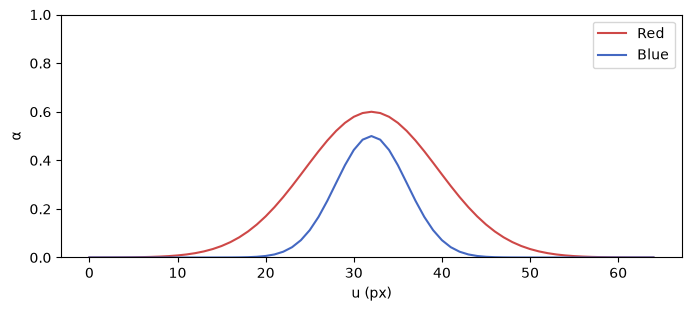

In [3]:
fig = demo.visibility_profile("en")
display(fig)
plt.close(fig)

## How much of the pixel is left?

An empty scene leaves one whole pixel available. We call the remaining fraction $T$ for transmittance, the share passed by the preceding layers. Red has $\alpha_1=0.6$ at the center. Its share is $1\cdot0.6=0.6$. The fraction left is $T=1\cdot(1-0.6)=0.4$. Blue has $\alpha_2=0.5$ and takes half of that remainder, $0.4\cdot0.5=0.2$. Another $0.4\cdot(1-0.5)=0.2$ goes to the white background.

Red is $(1,0,0)$, blue is $(0,0,1)$, and white is $(1,1,1)$. Each component ranges from zero to one. We multiply all three components by the layer's share, then add channel by channel.

$$
C=0.6(1,0,0)+0.2(0,0,1)+0.2(1,1,1)=(0.8,0.2,0.4).
$$

Reversing the order leaves the same share for the background. Blue now takes $0.5$ first and red gets $(1-0.5)0.6=0.3$. The result is $(0.5,0.2,0.7)$. The change is concentrated where both $\alpha$ values are large.

In [4]:
scene, camera = sr.overlap_scene(), sr.orbit_camera()
for u in (32, 38):
    remaining = 1.
    rgb = np.zeros(3)
    for item in sr.project_splats(scene, camera, 65, 65):
        alpha = sr.footprint_alpha([u, 32], item)
        rgb += remaining * alpha * item["color"]
        remaining *= 1 - alpha
    rgb += remaining * np.ones(3)
    np.testing.assert_allclose(rgb, sr.render_scene(scene, camera)[32, u])
    print(u, np.round(rgb, 6))

32 [0.8 0.2 0.4]
38 [0.905928 0.468656 0.562728]


## The layer's opacity and the layer's share

Blue says $0.5$ at the center but contributes only $0.2$ to the image. Those numbers answer different questions. If the blue splat hung alone against black, channel B would read $0.5$ at this opacity. Our scene also has red in front. Blue receives only $0.4$ of the original allowance, and keeping half of that contributes $0.2$. Its multiplier can be written $w_i=T_i\alpha_i$. Here $i$ is the position **in depth order**. If blue moves to the front when the camera orbits, both the index and the share change.

We already followed red at pixel $(38,32)$. Blue deserves the same trip all the way to the final channels. Its horizontal scale is $48\cdot0.38/4.5=4.0533$ px. The same six-pixel offset is about $1.480$ blue widths compared with $0.795$ red ones. Squaring gives $2.191$, the exponential gives $e^{-2.191/2}\approx0.3343$, and multiplication by the center opacity $0.5$ leaves $\alpha_B\approx0.1672$. For red we had $\alpha_R\approx0.4373$. The budget for a single ray can now be written down one row at a time.

| Next color | Available before layer | Color share | Available after |
|---|---:|---:|---:|
| Red | 1 | $1\cdot0.4373=0.4373$ | 0.5627 |
| Blue | 0.5627 | $0.5627\cdot0.1672\approx0.0941$ | 0.4687 |
| White background | 0.4687 | 0.4687 | 0 |

Blue ends up with nearly five times less weight than red. Of these three shares, the red channel receives the first and last, $0.4373+0.4687\approx0.906$. Green receives only the last, about $0.469$. Blue receives the middle and last ones, about $0.563$. The **RGB channels** need not add to one because they measure three independent intensities. The shares of the three sources add to one. Rounding the entries in the table can shift the last digit from the exact pixel in the code.

Against a black background the last share multiplies $(0,0,0)$. The first two shares stay put, so the result becomes approximately $(0.4373,0,0.0941)$. The difference between images on white and black is the same in each channel, $(0.4687,0.4687,0.4687)$. We have measured transmission without reading the internal array of alpha values. This experiment helps distinguish a background bug from an error in the splat’s own color. The comparison uses floating-point image values before any display color transform.

In [5]:
pix = (38, 32)
white = sr.render_scene(scene, camera, background=(1, 1, 1))
black = sr.render_scene(scene, camera, background=(0, 0, 0))
projected = sr.project_splats(scene, camera, 65, 65)
a, b = [sr.footprint_alpha(pix, item) for item in projected]
shares = np.array([a, (1-a)*b, (1-a)*(1-b)])
np.testing.assert_allclose(shares.sum(), 1)
np.testing.assert_allclose((white-black)[pix[1], pix[0]], shares[-1])
print("α =", np.round([a, b], 5), "   w =", np.round(shares, 5))
print("white − black =", np.round((white-black)[32,38], 5))

α = [0.43727 0.16717]    w = [0.43727 0.09407 0.46866]
white − black = [0.46866 0.46866 0.46866]


## How much can the order change a pixel?

The difference can be predicted before rendering the second image. Write $a,b$ for the red and blue opacities at this pixel and $r,s$ for their colors. Vector colors let one line of arithmetic handle all three channels. Ignoring the background for a moment, the normal order gives $ar+(1-a)bs$ and the reverse order gives $bs+(1-b)ar$. We could leave the background out because its share is the same both ways: $(1-a)(1-b)=(1-b)(1-a)$. Subtracting the second color from the first and opening the brackets gives

$$
\begin{aligned}
C_{rs}-C_{sr}
 &=ar+bs-abs-bs-ar+abr\\
 &=ab(r-s).
\end{aligned}
$$

This expression tells us how to read a difference image. When one Gaussian barely reaches a pixel, the product $ab$ is small whatever the color contrast. Two opaque layers of identical color also make the swap invisible because their color difference is zero. At the center of our cross $ab=0.6\cdot0.5=0.3$. In normal order red gains 0.3 units of intensity, blue loses the same amount, and green stays put. Six pixels to the right the product is $0.4373\cdot0.1672\approx0.0731$. Order still matters there, but a mistake is about four times less visible.

The first panel below shows how much of the pixel belongs to red, and the second shows how much is left for blue after red. The third shows the share of the background. Bright patches stand for large weights irrespective of the layer's actual color. The final panel shows the change in the red channel after a swap. The most visible difference should appear at the overlap of the two broad profiles. Checking against $ab$ tests both the ordering and whether the code has accidentally applied the transmission factor twice.

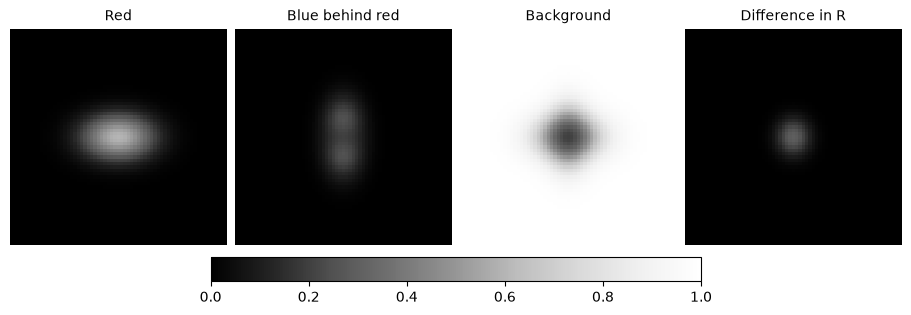

In [6]:
y, x = np.indices((65, 65))
pixels = np.stack((x, y), axis=-1)
a, b = [sr.footprint_alpha(pixels, item) for item in projected]
reverse = sr.render_scene(scene, camera, reverse=True)
difference = white[..., 0] - reverse[..., 0]
np.testing.assert_allclose(difference, a*b, atol=1e-14)
titles = (["Красное", "Синее за красным", "Фон", "Разность R"]
          if lang == "ru" else ["Red", "Blue behind red", "Background", "Difference in R"])
fig, axes = plt.subplots(1, 4, figsize=(9, 3), layout="constrained")
for ax, values, title in zip(axes, [a, (1-a)*b, (1-a)*(1-b), difference], titles):
    im = ax.imshow(values, cmap="Greys_r", vmin=0, vmax=1)
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()
fig.colorbar(im, ax=axes, orientation="horizontal", shrink=.55, pad=.04)
plt.show()

## From the loop to a full frame

At pixel $p=(u,v)$ we start with a black accumulator $C=(0,0,0)$ and a remaining fraction $T=1$. At splat $i$ we add $T\alpha_i c_i$ to $C$, then replace $T$ with $T(1-\alpha_i)$. At the end we add $T c_{\rm bg}$, where $c_{\rm bg}$ is the background RGB. Uppercase $C$ belongs to the frame, lowercase $c_i$ to a single splat.

A tilted ellipse replaces two independent divisions with $q=\delta^\mathsf{T} S^{-1}\delta$. Here $\delta=p-m$ is the displacement in pixels from the projected center $m$; $S$ is screen covariance in squared pixels and $S^{-1}$ its inverse. The matrix first acts on the two-component offset. A dot product with the same offset then produces one dimensionless number. As before, the code uses it to compute $\alpha_i=o_i\exp(-q/2)$.

The camera drops centers at or behind its near depth of $0.05$, where dividing by depth no longer gives a useful footprint for this camera. It sorts the remaining centers once per frame. Two long intersecting ellipsoids can have different front edges along different rays. Center sorting gives them one order across the image. When two center depths nearly coincide, a change in order can cause a visible jump in color.

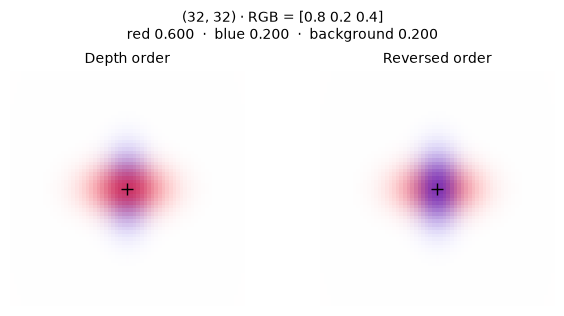

In [7]:
fig = demo.visibility_figure("en")
display(fig)
plt.close(fig)

## The camera goes around the cross

Both splats remain fixed in the world while the camera orbits to $120^\circ$. The file still says $z=3.5$ for red and $z=4.5$ for blue. These numbers have ceased to tell us the order. We need depth along the current line of sight. As in lesson 10, this is the third coordinate **after** subtracting the camera position and rotating into its frame.

This particular orbit admits a calculation without a large matrix. The camera is four meters from its target $(0,0,4)$ and points straight at it. The target depth is four at every angle. Relative to the target, red sits at $-0.5$ along world $z$ and blue at $+0.5$. The part of either offset that points along the camera is its length times the cosine of the angle. At zero degrees this is the whole offset, at $90^\circ$ it vanishes, and at $120^\circ$ it is half the offset with the opposite sign. The depths in the final position become $4+(-0.5)(-0.5)=4.25$ and $4+(+0.5)(-0.5)=3.75$. Blue goes first.

The orbit also moves the splats to different columns. The horizontal offset of red in camera coordinates is $-(-0.5)\sin120^\circ\approx0.433$ m. Blue has a negative offset of equal size. Dividing each by **its own** depth gives $32+48\cdot0.433/4.25\approx36.89$ and $32-48\cdot0.433/3.75\approx26.46$. At $(32,32)$ we now see the tails of both splats. First blue takes $0.1166$, then red gets about $(1-0.1166)\cdot0.3160=0.2791$, leaving $0.6043$ for white. The resulting color is $(0.8834,0.6043,0.7209)$. Merely swapping colors at the old center would have produced the wrong frame. A camera change updates centers, shape, and ordering together.

Viewed from the side at $90^\circ$, the center depths coincide. Our sort preserves file order on a tie. Physics did not grant red any priority. This is an implementation decision, and a small rounding difference can break a tie. In this example only the narrow tails overlap at that point. Making both splats very broad would reveal a more noticeable jump as the order changes. A geometric event, the depth swap, causes a visible change only where the product $ab$ is large enough.

  0° [(0, np.float64(3.5), np.float64(32.0)), (1, np.float64(4.5), np.float64(32.0))]  RGB [0.8 0.2 0.4]
 60° [(0, np.float64(3.75), np.float64(37.54)), (1, np.float64(4.25), np.float64(27.11))]  RGB [0.8785 0.6397 0.7613]
120° [(1, np.float64(3.75), np.float64(26.46)), (0, np.float64(4.25), np.float64(36.89))]  RGB [0.8834 0.6043 0.7209]


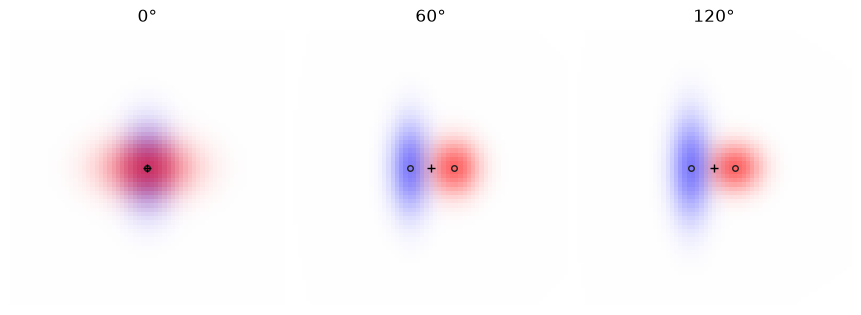

In [8]:
for angle in (0, 60, 120):
    cam = sr.orbit_camera(angle)
    items = sr.project_splats(scene, cam, 65, 65)
    print(f"{angle:3}°", [(q["index"], round(q["depth"], 2), round(q["mean"][0], 2)) for q in items],
          " RGB", np.round(sr.render_scene(scene, cam)[32, 32], 4))
fig, axes = plt.subplots(1, 3, figsize=(8.5, 3), layout="constrained")
for ax, angle in zip(axes, [0, 60, 120]):
    cam = sr.orbit_camera(angle)
    ax.imshow(sr.render_scene(scene, cam))
    for spot in sr.project_splats(scene, cam, 65, 65):
        ax.plot(*spot["mean"], "o", ms=4, mfc="none", mec="#222")
    ax.plot(32, 32, "+k")
    ax.set_title(f"{angle}°")
    ax.set_axis_off()
plt.show()

## When the loop can stop

So far there have been two layers. Suppose the ray now meets a stack of layers, each with $\alpha=0.5$ at our pixel. Half passes the first layer, a quarter passes both, and an eighth passes three. Ten layers leave $(1/2)^{10}=1/1024\approx0.000977$. The remaining colors are unknown, but every channel in this experiment lies between zero and one. Replacing that entire tail by black introduces at most $1/1024$ error in a channel. The same bound applies if the tail is replaced by white. On a 0–255 scale this is less than $0.25$ intensity units before rounding.

Where does the guarantee come from? Before layer $i$ a fraction $T_i$ is available, and the layer takes $w_i=T_i\alpha_i$. The remainder is $T_{i+1}=T_i(1-\alpha_i)$. Subtraction gives $T_i-T_{i+1}=w_i$. Summing across the stack cancels all the intermediate remainders, leaving $\sum_i w_i+T_{\rm end}=1$. The unknown tail can only redistribute the weight that actually remains. The teaching renderer visits every layer. For a large cloud this calculation tells us when continuing costs work for little visible change. The criterion depends on $T$ at this particular pixel. At the edge of a neighboring splat, those same ten layers might let through much more light.

## Experiments and worked answers

What happens at the center if blue disappears? From which angle does swapping the layers barely matter?

<details><summary>Worked answer</summary>

When $\alpha_2=0$, the result is $0.6(1,0,0)+0.4(1,1,1)=(1,0.4,0.4)$. From the side the footprints barely overlap, so one factor in $\alpha_1\alpha_2$ is small at nearly every pixel. Subtracting the two orders gives $\alpha_1\alpha_2(c_1-c_2)$, or $0.3(1,0,-1)$ at the center of the original example.

</details>

**A green layer appears between the splats.** At the central pixel its $\alpha$ is $0.25$. What is the new RGB on white for the order red, green, blue?

<details><summary>Worked answer</summary>

Red leaves $0.4$. Green takes $0.4\cdot0.25=0.1$ and passes $0.3$. Blue takes half of $0.3$, or $0.15$. The background receives the final $0.15$. The shares sum to $0.6+0.1+0.15+0.15=1$. Adding the pure colors and the white background gives $(0.75,0.25,0.30)$. The green channel rose by less than the new layer’s opacity because only part of the original allowance reached it.

</details>

**A dim red center.** On black the center of one red splat reads $(0.36,0,0)$ instead of $(0.6,0,0)$. The $\alpha$ in the table is correct. What could have happened to its color?

<details><summary>Worked answer</summary>

$0.36$ is $0.6^2$. The stored color may already include opacity, making it $(0.6,0,0)$. Our loop expects straight RGB and multiplies it again by $T\alpha=0.6$. A color that already contains alpha would need only the additional factor $T$. One layer against black removes both ordering and background contributions from the diagnosis.

</details>

**A nearly transparent edge in front of a dense center.** The front layer has $\alpha=0.01$ and the next has $\alpha=0.9$. Is a small contribution from the first layer a good reason to stop there?

<details><summary>Worked answer</summary>

The first layer passes $0.99$, and the dense center behind it gets $0.99\cdot0.9=0.891$ of the pixel. Dropping it because the first layer was weak can change almost the whole frame. A small $\alpha$ bounds the cost of dropping a single layer. A small accumulated remainder $T$ bounds the contribution of **everything** still to come.

</details>